# ДЗ по TF-IDF
1. Воспроизведение ноутбука с занятия
2. Несколько непохожих коротких предложений + векторный поиск
3. Тестовый корпус, разбиение на блоки, зависимость результатов поиска от размера и числа блоков
4. Стемминг на большом объёме текста: поиск со стеммингом и без

In [1]:
import re, time
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from nltk.stem.snowball import SnowballStemmer

pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)

## 1. Ноутбук с занятия

In [2]:
documents = [
    "Робот собрал данные с поверхности Луны",
    "Бабушка испекла свежий яблочный пирог",
    "Робот срубил дерево",
    "Банк резко повысил ставку по ипотеке",
]
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(documents)
df_tfidf = pd.DataFrame(tfidf_matrix.toarray(),
                        columns=vectorizer.get_feature_names_out(),
                        index=[f"Doc {i}" for i in range(len(documents))])
print("TF-IDF TABLE")
display(df_tfidf.round(2))

query = ["расстояние до луны"]
similarities = cosine_similarity(vectorizer.transform(query), tfidf_matrix).flatten()
print(f"\n--- RESULTS OF SEARCH: {query} ---")
for i in similarities.argsort()[::-1]:
    if similarities[i] > 0:
        print(f"[Similarity: {similarities[i]:.2f}] -> {documents[i]}")

TF-IDF TABLE


,бабушка,банк,данные,дерево,ипотеке,испекла,луны,пирог,по,поверхности,повысил,резко,робот,свежий,собрал,срубил,ставку,яблочный
Doc 0,0.00,0.00,0.47,0.00,0.00,0.00,0.47,0.00,0.00,0.47,0.00,0.00,0.37,0.00,0.47,0.00,0.00,0.00
Doc 1,0.45,0.00,0.00,0.00,0.00,0.45,0.00,0.45,0.00,0.00,0.00,0.00,0.00,0.45,0.00,0.00,0.00,0.45
Doc 2,0.00,0.00,0.00,0.62,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.49,0.00,0.00,0.62,0.00,0.00
Doc 3,0.00,0.41,0.00,0.00,0.41,0.00,0.00,0.00,0.41,0.00,0.41,0.41,0.00,0.00,0.00,0.00,0.41,0.00



--- RESULTS OF SEARCH: ['расстояние до луны'] ---
[Similarity: 0.47] -> Робот собрал данные с поверхности Луны


In [3]:
# Стемминг из занятия: инвертированный индекс по основам слов
from collections import defaultdict
stemmer = SnowballStemmer("russian")

docs_stem = [
    "Опытные программисты написали новые программы для обучения студентов",
    "Ветеринар лечил животных, используя современные медицинские программы",
    "Студенты изучали алгоритмы и программировали на языке Python",
]
stem_index, stem_to_original = defaultdict(set), defaultdict(set)
for doc_id, doc in enumerate(docs_stem):
    for word in re.findall(r"\w+", doc.lower()):
        s = stemmer.stem(word)
        stem_index[s].add(doc_id)
        stem_to_original[s].add(word)

def stem_search(query):
    stems = {stemmer.stem(w) for w in re.findall(r"\w+", query.lower())}
    found = sorted(set().union(*[stem_index[s] for s in stems if s in stem_index]))
    return stems, found

stems, found = stem_search("новая программа")
print("Основы запроса:", stems)
for d in found:
    print(f"Doc {d}: {docs_stem[d]}")

Основы запроса: {'нов', 'программ'}
Doc 0: Опытные программисты написали новые программы для обучения студентов
Doc 1: Ветеринар лечил животных, используя современные медицинские программы


## 2. Несколько непохожих коротких предложений и векторный поиск
Восемь предложений на разные темы. Запросы подобраны так, чтобы проверить: точное совпадение слов, другая словоформа, синоним, отсутствие совпадений.

In [4]:
sentences = [
    "Робот собрал данные с поверхности Луны",
    "Бабушка испекла свежий яблочный пирог",
    "Банк резко повысил ставку по ипотеке",
    "Сборная по хоккею выиграла чемпионат мира",
    "Врач назначил пациенту антибиотики при ангине",
    "Школьники написали контрольную по математике",
    "Новый смартфон получил мощный процессор и яркий экран",
    "Туристы отправились в горы с палатками и рюкзаками",
]
queries = [
    "данные с Луны",                  # точное совпадение слов
    "ставки по ипотеке в банках",     # другие словоформы: ставки/ставку, банках/банк
    "горы и палатка",                 # палатка != палатками
    "компьютер",                      # синоним: в корпусе только «смартфон»
    "лечение ангины",                 # «лечение» ≠ «назначил»; совпадает только «ангины»
]

def run(vec, docs, qs, k=2):
    X = vec.fit_transform(docs)
    for q in qs:
        s = cosine_similarity(vec.transform([q]), X).ravel()
        print(f"Запрос: «{q}»")
        if s.max() == 0:
            print("   (ни одного совпадения, косинус = 0 для всех документов)")
        for i in s.argsort()[::-1][:k]:
            if s[i] > 0:
                print(f"   {s[i]:.3f}  {docs[i]}")
    return X

print("=== TF-IDF без стемминга ===")
vec_plain = TfidfVectorizer()
X = run(vec_plain, sentences, queries)
print("\nРазмер словаря:", len(vec_plain.vocabulary_))

=== TF-IDF без стемминга ===
Запрос: «данные с Луны»
   0.632  Робот собрал данные с поверхности Луны
Запрос: «ставки по ипотеке в банках»
   0.525  Банк резко повысил ставку по ипотеке
   0.199  Школьники написали контрольную по математике
Запрос: «горы и палатка»
   0.447  Туристы отправились в горы с палатками и рюкзаками
Запрос: «компьютер»
   (ни одного совпадения, косинус = 0 для всех документов)
Запрос: «лечение ангины»
   (ни одного совпадения, косинус = 0 для всех документов)

Размер словаря: 43


In [5]:
stemmer = SnowballStemmer("russian")
WORD = re.compile(r"\w+", re.U)
tok = lambda s: WORD.findall(s.lower())
_cache = {}
def stem_word(w):
    r = _cache.get(w)
    if r is None:
        r = _cache[w] = stemmer.stem(w)
    return r
stem_tok = lambda s: [stem_word(w) for w in tok(s)]

print("=== TF-IDF со стеммингом (Snowball, русский) ===")
vec_stem = TfidfVectorizer(tokenizer=stem_tok, lowercase=False, token_pattern=None)
X = run(vec_stem, sentences, queries)
print("\nРазмер словаря:", len(vec_stem.vocabulary_))

=== TF-IDF со стеммингом (Snowball, русский) ===
Запрос: «данные с Луны»
   0.688  Робот собрал данные с поверхности Луны
   0.157  Туристы отправились в горы с палатками и рюкзаками
Запрос: «ставки по ипотеке в банках»
   0.705  Банк резко повысил ставку по ипотеке
   0.173  Туристы отправились в горы с палатками и рюкзаками
Запрос: «горы и палатка»
   0.604  Туристы отправились в горы с палатками и рюкзаками
   0.154  Новый смартфон получил мощный процессор и яркий экран
Запрос: «компьютер»
   (ни одного совпадения, косинус = 0 для всех документов)
Запрос: «лечение ангины»
   0.408  Врач назначил пациенту антибиотики при ангине

Размер словаря: 46


## 3. Тестовый корпус и разбиение на блоки
**Материалы.** Русские новостные статьи (датасет Gazeta, тестовая часть, ~6.8 тыс. статей на самые разные темы: политика, спорт, наука, экономика, культура). Берём случайную выборку статей, у каждой оставляем первые 300 слов, и склеиваем всё в один непрерывный текст.

**Как делим на блоки.** Непрерывный текст режем на блоки по `B` слов (без перекрытия). Границы блоков не совпадают с границами статей, как это и бывает при нарезке реальных документов.

**Как измеряем качество поиска.** Запрос — заголовок статьи (он написан другими словами, чем текст, поэтому это честная проверка). Релевантные блоки — те, в которые попал текст этой статьи. Метрики: `hit@1`, `hit@5` (есть ли релевантный блок первым / в первой пятёрке) и `MRR`. Для честности считаем и «случайный уровень»: какова вероятность попасть в релевантный блок, если выбирать блок наугад (он растёт с размером блока, потому что каждая статья занимает всё большую долю блоков).

In [6]:
import os
PATH = os.environ.get("GAZETA", "data/gazeta_test.parquet")
if not os.path.exists(PATH):                      # корпус скачивается один раз (30 МБ)
    import urllib.request; os.makedirs(os.path.dirname(PATH) or ".", exist_ok=True)
    urllib.request.urlretrieve("https://huggingface.co/datasets/IlyaGusev/gazeta/resolve/main/default/test/0000.parquet", PATH)
raw = pd.read_parquet(PATH, columns=["title", "text"])
print("Статей в датасете:", len(raw))

N_MAX, N_Q, TRUNC = 3200, 200, 300
arts = raw.sample(N_MAX, random_state=42).reset_index(drop=True)
art_words = [tok(t)[:TRUNC] for t in arts["text"]]
titles = arts["title"].tolist()
print("Слов в одной статье (после усечения): среднее", round(np.mean([len(w) for w in art_words]), 1))
print("Пример заголовка:", titles[0])
print("Фрагмент текста: ", " ".join(art_words[0][:25]), "...")

Статей в датасете: 6793


Слов в одной статье (после усечения): среднее 300.0
Пример заголовка: Обвиненный в секс-каннибализме актер отказался от «свадьбы» с Дженнифер Лопес 
Фрагмент текста:  актер арми хаммер ответил на обвинения в фантазиях о каннибализме в которых его на днях уличили пользователи соцсетей по словам 34 летней звезды фильмов социальная ...


In [7]:
def make_blocks(n_art, B):
    words, spans = [], []
    for a in range(n_art):
        spans.append((len(words), len(words) + len(art_words[a])))
        words += art_words[a]
    blocks = [" ".join(words[i:i + B]) for i in range(0, len(words), B)]
    return blocks, spans

def evaluate(n_art, B, stem=False):
    blocks, spans = make_blocks(n_art, B)
    vec = TfidfVectorizer(tokenizer=stem_tok if stem else tok, lowercase=False, token_pattern=None)
    X = vec.fit_transform(blocks)
    S = cosine_similarity(vec.transform(titles[:N_Q]), X)
    ranks, chance, nomatch, rels = [], [], 0, []
    for q in range(N_Q):
        s, e = spans[q]
        rel = np.arange(s // B, (e - 1) // B + 1)
        best = S[q, rel].max()
        rank = len(blocks) if best == 0 else 1 + int((S[q] > best).sum())
        ranks.append(rank); chance.append(len(rel) / len(blocks)); rels.append(len(rel))
        nomatch += S[q].max() == 0
    ranks = np.array(ranks)
    return dict(blocks=len(blocks), vocab=len(vec.vocabulary_),
                nnz_per_block=round(X.nnz / X.shape[0], 1),
                top1_score=round(float(S.max(1).mean()), 3),
                rel_blocks=round(float(np.mean(rels)), 1),
                chance_hit1=round(float(np.mean(chance)), 4),
                hit1=round(float((ranks == 1).mean()), 3),
                hit5=round(float((ranks <= 5).mean()), 3),
                MRR=round(float((1 / ranks).mean()), 3))

### 3.1. Размер блока (число блоков меняется вместе с размером), корпус фиксирован: 800 статей

In [8]:
t = time.time()
rows = []
for B in [10, 25, 50, 100, 200, 400, 800, 1600]:
    rows.append({"B (слов в блоке)": B, **evaluate(800, B)})
res_B = pd.DataFrame(rows).set_index("B (слов в блоке)")
print(f"({time.time()-t:.0f} с)")
res_B

(2 с)


,blocks,vocab,nnz_per_block,top1_score,rel_blocks,chance_hit1,hit1,hit5,MRR
B (слов в блоке),,,,,,,,,
10,24000,41938,9.9,0.346,30.0,0.0012,0.515,0.720,0.611
25,9600,41938,23.8,0.273,12.0,0.0012,0.590,0.765,0.674
50,4800,41938,45.4,0.239,6.0,0.0012,0.620,0.810,0.701
100,2400,41938,84.8,0.215,3.0,0.0012,0.630,0.810,0.718
200,1200,41938,157.6,0.185,2.0,0.0017,0.670,0.840,0.746
400,600,41938,292.6,0.158,1.5,0.0025,0.665,0.845,0.745
800,300,41938,543.6,0.128,1.2,0.0042,0.650,0.840,0.731
1600,150,41938,1001.5,0.104,1.1,0.0075,0.665,0.815,0.734


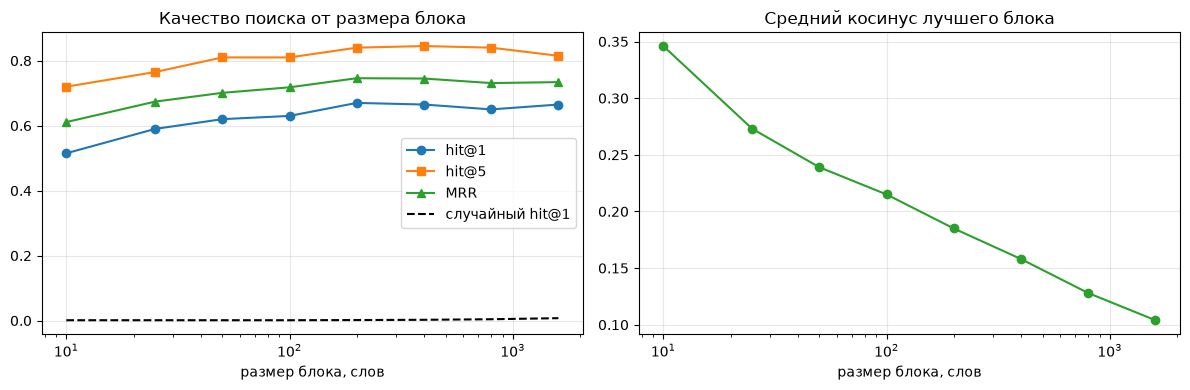

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(res_B.index, res_B["hit1"], "o-", label="hit@1")
ax[0].plot(res_B.index, res_B["hit5"], "s-", label="hit@5")
ax[0].plot(res_B.index, res_B["MRR"], "^-", label="MRR")
ax[0].plot(res_B.index, res_B["chance_hit1"], "k--", label="случайный hit@1")
ax[0].set_xscale("log"); ax[0].set_xlabel("размер блока, слов"); ax[0].set_title("Качество поиска от размера блока"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(res_B.index, res_B["top1_score"], "o-", color="tab:green")
ax[1].set_xscale("log"); ax[1].set_xlabel("размер блока, слов"); ax[1].set_title("Средний косинус лучшего блока"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("tfidf_block_size.png", dpi=140); plt.show()

### 3.2. Число блоков при фиксированном размере блока (B = 100 слов): растёт корпус

In [10]:
rows = []
for n in [200, 400, 800, 1600, 3200]:
    rows.append({"статей в корпусе": n, **evaluate(n, 100)})
res_N = pd.DataFrame(rows).set_index("статей в корпусе")
res_N

,blocks,vocab,nnz_per_block,top1_score,rel_blocks,chance_hit1,hit1,hit5,MRR
статей в корпусе,,,,,,,,,
200,600,17428,84.5,0.218,3.0,0.0050,0.765,0.905,0.825
400,1200,27394,84.6,0.216,3.0,0.0025,0.715,0.865,0.779
800,2400,41938,84.8,0.215,3.0,0.0012,0.630,0.810,0.718
1600,4800,62423,85.0,0.218,3.0,0.0006,0.600,0.760,0.679
3200,9600,90228,85.1,0.222,3.0,0.0003,0.530,0.720,0.624


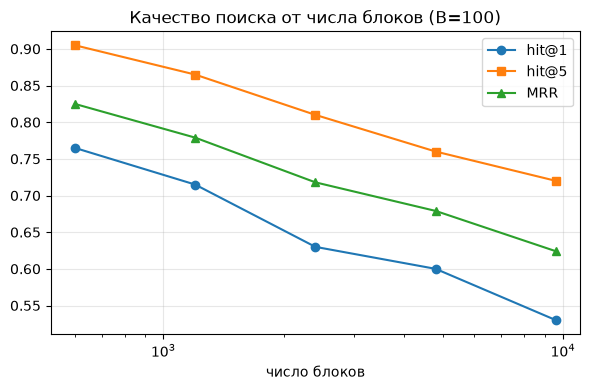

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(res_N["blocks"], res_N["hit1"], "o-", label="hit@1")
ax.plot(res_N["blocks"], res_N["hit5"], "s-", label="hit@5")
ax.plot(res_N["blocks"], res_N["MRR"], "^-", label="MRR")
ax.set_xscale("log"); ax.set_xlabel("число блоков"); ax.set_title("Качество поиска от числа блоков (B=100)")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.savefig("tfidf_block_count.png", dpi=140); plt.show()

## 4. Стемминг на большом объёме текста

In [12]:
rows = []
for B in [25, 100, 400]:
    for stem in (False, True):
        rows.append({"B": B, "стемминг": "да" if stem else "нет", **evaluate(800, B, stem)})
res_S = pd.DataFrame(rows).set_index(["B", "стемминг"])
res_S[["blocks", "vocab", "nnz_per_block", "top1_score", "hit1", "hit5", "MRR"]]

blocks  vocab  nnz_per_block  top1_score   hit1   hit5    MRR
B   стемминг                                                               
25  нет         9600  41938           23.8       0.273  0.590  0.765  0.674
    да          9600  18917           23.5       0.345  0.680  0.840  0.757
100 нет         2400  41938           84.8       0.215  0.630  0.810  0.718
    да          2400  18917           80.1       0.300  0.740  0.890  0.806
400 нет          600  41938          292.6       0.158  0.665  0.845  0.745
    да           600  18917          259.4       0.240  0.740  0.890  0.807

In [13]:
# Большой корпус целиком: 3200 статей, блоки по 100 слов
rows = []
for stem in (False, True):
    t = time.time()
    r = evaluate(3200, 100, stem)
    rows.append({"стемминг": "да" if stem else "нет", **r, "сек": round(time.time() - t, 1)})
pd.DataFrame(rows).set_index("стемминг")[["blocks", "vocab", "top1_score", "hit1", "hit5", "MRR", "сек"]]

,blocks,vocab,top1_score,hit1,hit5,MRR,сек
стемминг,,,,,,,
нет,9600,90228,0.222,0.53,0.720,0.624,0.8
да,9600,37096,0.314,0.66,0.805,0.730,1.6


In [14]:
# Где стемминг помог / навредил: сравним ранг релевантного блока для каждого запроса
def ranks_for(n_art, B, stem):
    blocks, spans = make_blocks(n_art, B)
    vec = TfidfVectorizer(tokenizer=stem_tok if stem else tok, lowercase=False, token_pattern=None)
    X = vec.fit_transform(blocks)
    S = cosine_similarity(vec.transform(titles[:N_Q]), X)
    out = []
    for q in range(N_Q):
        s, e = spans[q]
        rel = np.arange(s // B, (e - 1) // B + 1)
        best = S[q, rel].max()
        out.append(len(blocks) if best == 0 else 1 + int((S[q] > best).sum()))
    return np.array(out)

r0, r1 = ranks_for(3200, 100, False), ranks_for(3200, 100, True)
print(f"Запросов: {N_Q}. Стемминг улучшил ранг: {(r1 < r0).sum()}, ухудшил: {(r1 > r0).sum()}, без изменений: {(r1 == r0).sum()}")
print("\nПримеры, где стемминг помог больше всего:")
for q in np.argsort(r1 - r0)[:5]:
    print(f"  ранг {r0[q]:>5} -> {r1[q]:>5} | {titles[q]}")
print("\nПримеры, где стемминг ухудшил результат:")
for q in np.argsort(r0 - r1)[:5]:
    print(f"  ранг {r0[q]:>5} -> {r1[q]:>5} | {titles[q]}")

Запросов: 200. Стемминг улучшил ранг: 62, ухудшил: 36, без изменений: 102

Примеры, где стемминг помог больше всего:
  ранг  2934 ->    21 | Эксперты рассказали, из-за чего осенью разгонится инфляция 
  ранг   762 ->     1 | В деле Сомертонского человека появился новый свидетель 
  ранг  1167 ->   409 | Вирусолог назвал срок стабилизации ситуации с коронавирусом в России 
  ранг   613 ->   129 | Суточная заболеваемость COVID в Москве достигла максимума с начала года 
  ранг   268 ->     6 | Биологи обнаружили рыбу, живущую сто лет 

Примеры, где стемминг ухудшил результат:
  ранг  5665 ->  6599 | «Заклятие 3»: как все было в действительности 
  ранг    97 ->   354 | Как телеграм-каналы отреагировали на новые санкции Вашингтона 
  ранг   461 ->   575 | В МИД назвали количество россиян, отбывающих срок в зарубежных тюрьмах 
  ранг    43 ->   155 | Белоруссия отказывается от бизнеса с Литвой 
  ранг     9 ->    85 | Что интересовало телеграм-каналы на прошлой неделе 


In [15]:
# Что делает стеммер: сколько разных словоформ сворачивается в одну основу и где он ошибается
from collections import defaultdict
forms = defaultdict(set)
vocab_plain = set(w for ws in art_words[:3200] for w in ws)
for w in vocab_plain:
    forms[stem_word(w)].add(w)
print("Уникальных словоформ:", len(vocab_plain), "-> уникальных основ:", len(forms),
      f"(сжатие словаря в {len(vocab_plain)/len(forms):.2f} раза)")
big = sorted(forms.items(), key=lambda kv: -len(kv[1]))
print("\nОсновы с наибольшим числом словоформ:")
for s, f in big[:6]:
    print(f"  {s!r}: {len(f)} форм, напр. {sorted(f)[:8]}")
print("\nОшибки стеммера (разные слова -> одна основа, over-stemming):")
for s in ["рос", "стол", "пол", "мир", "вод"]:
    cand = sorted(forms.get(s, []))
    if cand: print(f"  {s!r}: {cand[:12]}")
print("\nНедостемминг (одно слово -> разные основы):")
for a, b in [("человек", "люди"), ("ребенок", "дети"), ("идти", "шёл")]:
    print(f"  {a!r} -> {stem_word(a)!r}, {b!r} -> {stem_word(b)!r}")

Уникальных словоформ: 90228 -> уникальных основ: 37096 (сжатие словаря в 2.43 раза)

Основы с наибольшим числом словоформ:
  'созда': 40 форм, напр. ['создав', 'создавшаяся', 'создавшего', 'создавшей', 'создавшейся', 'создавшие', 'создавший', 'создавшихся']
  'занима': 38 форм, напр. ['занимавшаяся', 'занимавшего', 'занимавшегося', 'занимавшие', 'занимавший', 'занимавшийся', 'занимавшихся', 'занимаемой']
  'продолжа': 35 форм, напр. ['продолжавшегося', 'продолжавшееся', 'продолжавшиеся', 'продолжавшийся', 'продолжавших', 'продолжаем', 'продолжает', 'продолжается']
  'призна': 33 форм, напр. ['признав', 'признавший', 'признавшую', 'признаем', 'признает', 'признается', 'признай', 'признал']
  'готов': 33 форм, напр. ['готова', 'готовившего', 'готовившийся', 'готовивших', 'готовившую', 'готовил', 'готовила', 'готовилась']
  'получ': 32 форм, напр. ['получая', 'получен', 'получена', 'получено', 'получены', 'получив', 'получившая', 'получившего']

Ошибки стеммера (разные слова -> одна основ